# Basic map with small regions

Basic example of making grid from geojson.

## Code setup

In [1]:
import os
from dataclasses import dataclass

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt

# Add path to package:
import sys
sys.path.insert(0,'../')
import isopods.grid
import isopods.stick
import isopods.convert

In [2]:
@dataclass(frozen=True)
class Paths:
    '''Singleton object for storing paths to data and database.'''

    dir_data: str = '../data'
    lsoa_filename: str = 'lsoa2011_devon.geojson'

paths = Paths()

## Load data

LSOA shapes for Devon. Make sure the GeoDataFrame index is the label for each region.

In [3]:
p = os.path.join(paths.dir_data, paths.lsoa_filename)
gdf = gpd.read_file(p).set_index('LSOA11CD')
gdf['geometry'] = gdf.make_valid()

In [4]:
gdf.head(3)

,FID,LSOA11NM,LSOA11NMW,BNG_E,BNG_N,LONG,LAT,GlobalID,area_name,geometry
LSOA11CD,,,,,,,,,,
E01015023,14568,Plymouth 003A,Plymouth 003A,247552,60231,-4.14743,50.42208,6e00dc30-ff9b-4373-a273-8f83ac4f0e43,Plymouth,"POLYGON ((247801.375 60189.402, 247893.675 602..."
E01015024,14569,Plymouth 004A,Plymouth 004A,246298,60366,-4.16512,50.42297,70bf14eb-d03d-425f-804c-8f8fb0266310,Plymouth,"POLYGON ((246716.109 60750.531, 246946.495 608..."
E01015025,14570,Plymouth 001A,Plymouth 001A,249392,60203,-4.12153,50.42231,05f33914-7f44-48a6-aef2-983de4417eab,Plymouth,"POLYGON ((249720.786 60435.671, 249811.109 603..."


Check the coordinate reference system (CRS):

In [5]:
gdf.crs

<Projected CRS: EPSG:27700>
Name: OSGB36 / British National Grid
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: United Kingdom (UK) - offshore to boundary of UKCS within 49°45'N to 61°N and 9°W to 2°E; onshore Great Britain (England, Wales and Scotland). Isle of Man onshore.
- bounds: (-9.01, 49.75, 2.01, 61.01)
Coordinate Operation:
- name: British National Grid
- method: Transverse Mercator
Datum: Ordnance Survey of Great Britain 1936
- Ellipsoid: Airy 1830
- Prime Meridian: Greenwich

## Generate values for regions

Give a random value to each region:

In [6]:
np.random.seed(42)
gdf['value'] = np.random.randint(0, 11, len(gdf))

In [7]:
gdf['geometry'] = gdf.make_valid()

Calculate the size of each polygon:

In [8]:
gdf['geometry_area'] = gdf['geometry'].area

## Check the scales

What sizes are the shapes? What size of grid cell will make sense?

First view all of the shapes:

<Axes: >

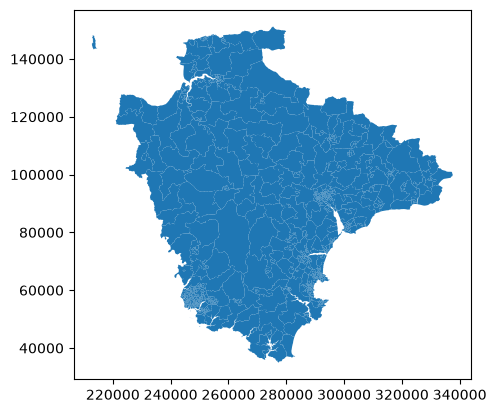

In [9]:
gdf.plot()

Now check the largest and smallest shapes:

In [10]:
lsoa_smallest = gdf.sort_values('geometry_area').index[0]
lsoa_largest = gdf.sort_values('geometry_area', ascending=False).index[0]

In [11]:
print(' '*10, 'width (m)  height (m)')
for lsoa in (lsoa_smallest, lsoa_largest):
    bbox = gdf.loc[lsoa, 'geometry'].bounds
    width = bbox[2] - bbox[0]
    height = bbox[3] - bbox[1]
    print(f'{lsoa:9s} {width:>10.1f}  {height:>10.1f}')

           width (m)  height (m)
E01015053      493.2       432.8
E01020323    19096.0     26112.4


The smallest LSOA (in Plymouth) is around 40 to 50 times smaller than the largest LSOA (in West Devon) in each direction. Clearly the same size scale won't make sense for both LSOA.

For now, choose a fairly small cell size and see how it goes.

## Set up grid

First, find the bounding box to see the spatial extent of the shapes:

In [12]:
bbox_shapes = gdf.total_bounds

bbox_shapes

array([212711.6182,  34957.4029, 337605.812 , 151204.9973])

We should define a grid that aligns nicely with the British National Grid. Instead of starting our grid at the top left corner of this bounding box, we'll start at the nearest sensible round number.

Say we want cells to be 3km across and tall. Then the nearest sensible starting points are:

In [13]:
cell_width = 3000  # metres
cell_height = 3000  # metres

bbox_grid = isopods.grid.make_grid_bounds_containing_bbox(
    bbox_shapes, cell_width, cell_height)

In [14]:
for b, g in zip(bbox_shapes, bbox_grid):
    print(f'{b:8.1f} {g:8.0f}')

212711.6   210000
 34957.4    33000
337605.8   339000
151205.0   153000


Make the transform dictionary based on these starting points:

In [15]:
# Prepare some variables
transform_dict = isopods.grid.make_transform_dict(
    bbox_grid, cell_width, cell_height)

In [16]:
transform_dict

{'xmin': np.float64(210000.0),
 'ymax': np.float64(153000.0),
 'cell_width': 3000,
 'cell_height': 3000,
 'n_cols': 43,
 'n_rows': 40,
 'xmax': np.float64(339000.0),
 'ymin': np.float64(33000.0)}

The grid will cover this extent:

In [17]:
extent = (transform_dict['xmin'], transform_dict['xmax'],
          transform_dict['ymin'], transform_dict['ymax'])

The grid starts from the top left of the bounding box and continues down and right in cells until it has made a cell that contains the bottom right of the bounding box.

## Stick shapes to grid

In [18]:
df_props = isopods.stick.stick_shapes_to_grid(
    gdf, **transform_dict, print_progress=True)

100.0% of cells checked

/home/anna/geography/isopods/01_tutorial/../isopods/stick.py:99: UserWarning: Overlapping polygons present in 7 cells: overlap area will be counted twice.
  warnings.warn((


Check the cells with overlapping values. Are the total areas covered greater than the cell area? If the proportion is much greater than 1, then the area that has been double-counted by the overlapping polygons will be significant.

In [19]:
(df_props.loc[df_props['overlapping_polys'] == 1]
 .sort_values('prop_cell_covered', ascending=False).head(3))

,cell_row,cell_col,label_props,area_props,prop_cell_covered,label_majority,overlapping_polys
cell_label,,,,,,,
552,32,13,"[E01020107, E01020119, E01020106, E01020105, E...","[0.524, 0.43, 0.036, 0.01, 0.0]",1.0,E01020107,1
568,8,14,"[E01020149, E01015120, E01015125, E01015121, E...","[0.567, 0.156, 0.073, 0.054, 0.045, 0.043, 0.0...",1.0,E01020149,1
711,31,17,"[E01020121, E01020097, E01020120]","[0.911, 0.088, 0.001]",1.0,E01020121,1


The `prop_cell_covered` column is always less than 1.001, so no problem here.

Pick out some cells containing the most shapes:

In [20]:
mask = df_props['label_props'].str.len() > 1
df_props[mask].head()

,cell_row,cell_col,label_props,area_props,prop_cell_covered,label_majority,overlapping_polys
cell_label,,,,,,,
189,29,4,"[E01020292, E01020291]","[0.758, 0.242]",0.956,E01020292,0
229,29,5,"[E01020291, E01020292]","[0.782, 0.218]",1.000,E01020291,0
263,23,6,"[E01020302, E01020293]","[0.994, 0.006]",0.998,E01020302,0
264,24,6,"[E01020302, E01020293]","[0.78, 0.22]",0.955,E01020302,0
265,25,6,"[E01020302, E01020291]","[0.995, 0.005]",0.718,E01020302,0


## Convert dataframe to 2D grid

Find the random value of the shape in each cell. In the previous notebook we first found the label of the majority region in each cell and then converted those labels to the data for plotting. Here we instead merge the data to plot into the proportions dataframe, and can then make the grid directly with that data.

In [21]:
df_props = pd.merge(df_props, gdf[['value', 'LAT']].reset_index(),
                    left_on='label_majority', right_on='LSOA11CD', how='left')

Remove cells that are under 50% full:

In [22]:
df_props = df_props[df_props['prop_cell_covered'] >= 0.5]

In [23]:
arr_values = isopods.convert.convert_df_to_2darray(
    df_props, 'value', **transform_dict)

In [24]:
arr_values

masked_array(
  data=[[--, --, --, ..., --, --, --],
        [--, --, --, ..., --, --, --],
        [--, --, --, ..., --, --, --],
        ...,
        [--, --, --, ..., --, --, --],
        [--, --, --, ..., --, --, --],
        [--, --, --, ..., --, --, --]],
  mask=[[ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True],
        ...,
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True]],
  fill_value=999999)

In [25]:
arr_lats = isopods.convert.convert_df_to_2darray(
    df_props, 'LAT', **transform_dict)

## Plot the grids

Setup for plotting:

In [26]:
# Set up colour map to exclude the "missing" value.
cmap_values = plt.get_cmap('viridis', len(gdf['value'].unique()))
cmap_values.set_under((1.0, 1.0, 1.0, 0.0))  # transparent

In [27]:
# Set up colour map to exclude the "missing" value.
cmap_lats = plt.get_cmap('plasma')

In [28]:
def plot_values_lats(ax_values, ax_lats, gdf, arr_values, arr_lats, extent,
                     cmap_values, cmap_lats):
    # Gridded values:
    cv = ax_values.imshow(arr_values, origin='lower', extent=extent,
                          vmin=gdf['value'].min(), vmax=gdf['value'].max(),
                          cmap=cmap_values)
    cl = ax_lats.imshow(arr_lats, origin='lower', extent=extent,
                        vmin=gdf['LAT'].min(), vmax=gdf['LAT'].max(),
                        cmap=cmap_lats)

    # Explicitly give cmap boundaries and values so that discrete
    # colours are drawn with ticks in the middle of the band.
    values_list = np.arange(gdf['value'].min(), gdf['value'].max() + 1, 1)
    boundaries_list = np.arange(gdf['value'].min() - 0.5,
                                gdf['value'].max() + 1.5, 1)
    cbar = plt.colorbar(cv, label='Random value',
                        boundaries=boundaries_list, values=values_list)
    cbar.set_ticks(values_list)
    
    plt.colorbar(cl, label='Latitude')

    # Shapes:
    for ax in [ax_values, ax_lats]:
        gdf.plot(ax=ax, facecolor='None', edgecolor='k')

### Devon

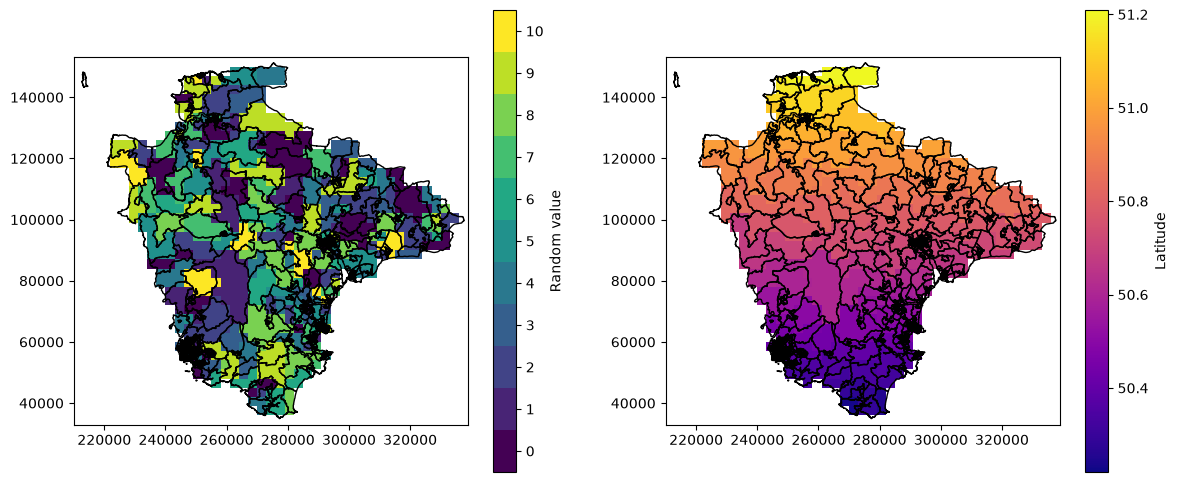

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
plot_values_lats(*axs, gdf, arr_values, arr_lats, extent,
                 cmap_values, cmap_lats)
plt.show()

This cell size looks pretty good when zoomed out this far. The grid follows the outline of the county well. However the cities and big towns have tightly-packed smaller LSOA and so it is difficult to see what is happening there in any detail.

### Exe estuary

Zoom in on an area containing Exeter, a city with many small LSOA.

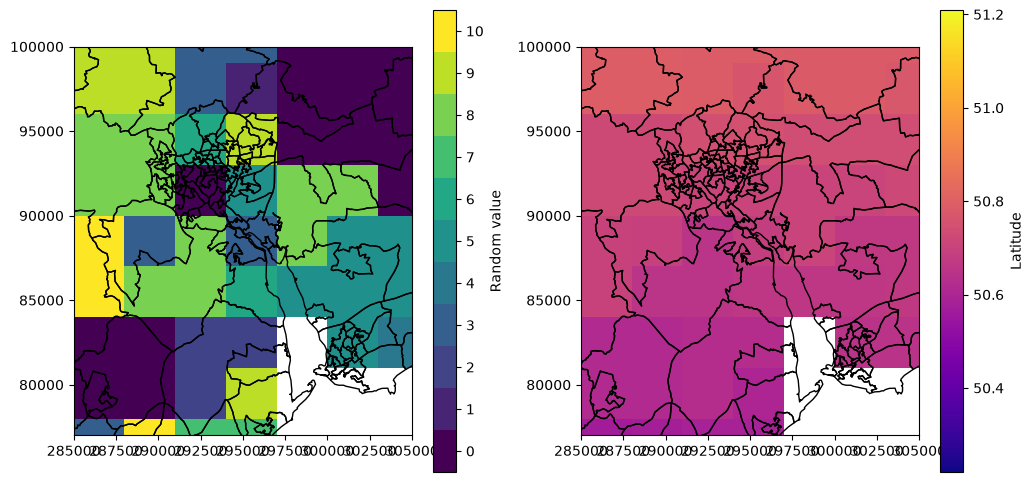

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
plot_values_lats(*axs, gdf, arr_values, arr_lats, extent,
                 cmap_values, cmap_lats)

for ax in axs:
    ax.set_xlim(285000, 305000)
    ax.set_ylim(77000, 100000)
plt.show()

The random value map looks awful in Exeter. The grid cells all contain several LSOA and it is difficult to see which shape has contributed to the cell colour.

However the latitude map looks fine because all of the adjacent shapes have similar latitudes. The lack of precision doesn't matter so much in this case.